# When does single-mode temporal coupled-mode theory fail under coherent two-port excitation?

This notebook reproduces every number and figure of the study from scratch. Running the cells
in order regenerates all intermediate data in `results/`, all figures in `figures/`, and the
summary table at the end. Nothing is read from disk that the notebook has not written itself.

**Question.** Single-mode temporal coupled-mode theory (TCMT) describes a resonance by one
complex pole on a constant background. Driving a two-port structure from both sides with a
controlled relative phase exposes the error of that description, because the off-resonant tails
of neighbouring resonances, which the single-mode model omits, interfere with the resonant
response. We measure this error against exact solutions and ask how large it is as a function
of the mode separation measured in linewidths, $x = \Delta/\gamma$.

**Plan.**

1. Theory: the TCMT models, the error functional, an exact law for its dependence on the
   excitation phase, and the tail strength that controls its magnitude.
2. Validation of both electromagnetic solvers against closed-form and independent results.
3. Cavity platform: realise 19 separations, measure the worst-case single-mode error, fit and
   validate the criterion, and test its sensitivity to the measurement window.
4. Mechanism: recovery by multimode models and collapse onto the tail strength.
5. Quality factor at fixed separation.
6. Transfer to a grating platform.
7. Summary of all reported numbers.

The full run takes about 70 minutes on one CPU core.

## 1. Theory

### 1.1 Single-mode and multimode TCMT

A resonance with complex amplitude $a$ (normalised so that $|a|^2$ is the stored energy)
coupled to two ports with incoming and outgoing amplitudes $s_+$ and $s_-$ (normalised so that
$|s|^2$ is power) obeys

$$\frac{da}{dt} = (i\omega_0 - \gamma)\,a + \boldsymbol{\kappa}^{T} s_+, \qquad
s_- = \mathbf{C}\,s_+ + a\,\mathbf{d}.$$

With time dependence $e^{-i\omega t}$ this gives

$$\mathbf{S}(\omega) = \mathbf{C} + \frac{\mathbf{d}\,\boldsymbol{\kappa}^{T}}{i(\omega_0-\omega)+\gamma}.$$

For a lossless reciprocal two-port, energy conservation and time reversal require
$\mathbf{d}^{\dagger}\mathbf{d} = 2\gamma$, $\mathbf{C}\mathbf{d}^{*} = -\mathbf{d}$ and
$\boldsymbol{\kappa} = \mathbf{d}$, with $\mathbf{C}$ unitary and symmetric, so that

$$\mathbf{S}(\omega) = \mathbf{C} + \frac{\mathbf{d}\,\mathbf{d}^{T}}{i(\omega_0-\omega)+\gamma}.$$

A model with $M$ modes sharing one background adds one rank-one term per mode,

$$\mathbf{S}(\omega) = \mathbf{C} + \sum_{m=1}^{M}
\frac{\mathbf{d}_m\mathbf{d}_m^{T}}{i(\omega_m-\omega)+\gamma_m}.$$

In the fits below the factor $\exp\{i[a_0 + b_0(\omega-\omega_{\mathrm{ref}})]\}$ multiplies the
whole model. It represents the position of the port reference planes: moving both planes
multiplies $\mathbf{S}$ by a common propagation phase that a constant $\mathbf{C}$ cannot
represent over a finite window. The lossless constraints are not imposed during fitting, so the
fitted model is the best member of the $M$-pole family on the window and its error is a lower
bound on that of any constrained model; how closely the fitted single-mode parameters satisfy
$|\mathbf{d}|^2 = 2\gamma$ is reported as a diagnostic.

Every fit is a local Levenberg–Marquardt search. The model families are nested: a constant
background is a linear background with zero slope, and an $M$-mode model is an $(M+2)$-mode
model with two zero couplings. Each extended model is therefore started both from a generic
initial point and from the optimum of the nested model, and the constant-background model is
restarted from the linear-background optimum with its slope removed. The fit with the lower
residual is kept, so an extended model never ends with a larger residual than the model it
contains, and a single-mode fit trapped in a poor local minimum is detected and repaired.

### 1.2 Coherent excitation and the error functional

The structure is driven by the normalised input
$s_+(\varphi) = (1, e^{i\varphi})/\sqrt{2}$, where $\varphi$ is the relative phase of the two
port amplitudes. The relative error of a model $\tilde{\mathbf{S}}$ over the $N$ frequencies of
a window is

$$E(x,\varphi) = \frac{\lVert \Delta\mathbf{S}\,s_+ \rVert}{\lVert \mathbf{S}\,s_+ \rVert},
\qquad \Delta\mathbf{S} = \tilde{\mathbf{S}} - \mathbf{S},$$

with the norm summed over frequency and ports. Near a destructive-interference minimum of one
output port the exact output is small while the model error is not, which is why coherent
drive exposes the single-mode error far more strongly than single-port drive.

**Measurement window.** The window is centred on the target resonance with half-width
$h = \min(0.4\,\Delta,\ 12\,\gamma)$, sampled at 1600 points. Twelve linewidths resolve the line
shape and its wings; the cap at $0.4\,\Delta$ keeps the neighbouring resonance outside the
window. The window is part of the definition of $E$, and Section 5.4 shows how the results
change when it is varied.

### 1.3 An exact law for the dependence on excitation phase

Both sums in $E^2$ are Hermitian quadratic forms in $s_+$:

$$E^{2}(\varphi) = \frac{s_+^{\dagger}\mathbf{M}\,s_+}{s_+^{\dagger}\mathbf{P}\,s_+},\qquad
\mathbf{M} = \sum_{\omega}\Delta\mathbf{S}^{\dagger}\Delta\mathbf{S},\qquad
\mathbf{P} = \sum_{\omega}\mathbf{S}^{\dagger}\mathbf{S}.$$

For $s_+ = (1, e^{i\varphi})/\sqrt{2}$ a Hermitian form evaluates to
$\tfrac12(M_{11}+M_{22}) + \mathrm{Re}(M_{12}e^{i\varphi})$, a constant plus a single harmonic.
When the reference structure is lossless, $\mathbf{S}$ is unitary at every frequency and
$\mathbf{P} = N\,\mathbf{I}$, so the denominator does not depend on $\varphi$ and

$$E^{2}(x,\varphi) = A(x)\,\bigl[1 + v(x)\cos(\varphi-\psi)\bigr],\qquad
A = \frac{M_{11}+M_{22}}{2N},\quad v = \frac{2|M_{12}|}{M_{11}+M_{22}},\quad
\psi = -\arg M_{12}.$$

This is an identity, not an approximation, and it holds for any model and any lossless two-port.
It has two consequences used throughout. First, the worst case over the excitation phase is
available in closed form,

$$E_{\max}(x) = \sqrt{A(x)\,[1+v(x)]},\qquad E_{\min}(x) = \sqrt{A(x)\,[1-v(x)]},$$

so the phase axis need not be sampled. Second, when the structure and the fitted model are
both mirror symmetric, $\Delta\mathbf{S}$ has equal diagonal entries and $M_{12}$ is real, which
pins $\psi$ to $0$ or $\pi$. In a lossy structure $\mathbf{P}$ acquires an off-diagonal part and
$E^2$ becomes a ratio of two harmonics.

### 1.4 Why neighbouring resonances produce the error: the tail strength

Let mode $j$ sit at detuning $\Delta_j = \omega_j - \omega_t$ from the target with decay rate
$\gamma_j$. Inside the window, $|\omega-\omega_t| \le h \ll |\Delta_j|$, its contribution
expands as

$$\frac{\mathbf{d}_j\mathbf{d}_j^{T}}{i(\omega_j-\omega)+\gamma_j}
\approx \frac{\mathbf{d}_j\mathbf{d}_j^{T}}{i\Delta_j}
\left[1 + \frac{\omega-\omega_t}{\Delta_j} + \cdots\right].$$

The constant term is indistinguishable from the background and is absorbed into
$\mathbf{C}$ when the single-mode model is fitted. The first term that the single-mode model
cannot represent is the linear one, whose size across the window is
$|\mathbf{d}_j|^2 h/\Delta_j^2 = 2\gamma_j h/\Delta_j^2$. Its sign does not depend on the side of
the target on which mode $j$ lies, so neighbours on both sides add. This motivates the
dimensionless tail strength

$$\tau = \sum_{j\neq t}\frac{2\,\gamma_j\,h}{\Delta_j^{2}},$$

and the expectation $E_{\max} \approx c\,\tau$ with an order-unity-or-smaller constant $c$ that
depends on how the tail projects onto the error and on the part absorbed by the reference-plane
phase. In a comb of equally broad modes with spacing $\Delta$ the sum is dominated by the two
adjacent modes: summing $2\gamma h/(j\Delta)^2$ over $j = \pm1, \pm2, \ldots$ gives
$\tau \approx (2\pi^2/3)\,\gamma h/\Delta^2$, of which the two adjacent modes supply 61%.
With the window above this gives $\tau \approx 2.6/x$ while $h = 0.4\Delta$ (that is, for
$x < 30$) and $\tau \approx 79/x^2$ once $h = 12\gamma$. The large-separation exponent of the criterion is
therefore set by the window convention, between $-1$ and $-2$, and is not a property of the
resonances alone. At small $x$ the expansion fails because the neighbours approach the window
edge; there the error saturates instead of growing as $1/x$.

### 1.5 Electromagnetic solvers

**Transfer-matrix method (cavity platform).** For a layer of index $n$ and thickness $d$ at
vacuum wavenumber $k_0$, forward and backward amplitudes acquire phases $e^{\pm i k_0 n d}$, and
an interface between media $a$ and $b$ is described by the Fresnel coefficients
$r = (n_a-n_b)/(n_a+n_b)$ and $t = 2n_a/(n_a+n_b)$. Multiplying the interface and propagation
matrices across the stack gives the reflection and transmission amplitudes exactly. The cavity
is a layer of $m = 30$ half-waves between quarter-wave Bragg mirrors; the mirror reflectivity
(number of periods and high index) sets the finesse and with it $x$, while the cavity length
sets the quality factor independently.

**Fourier modal method (grating platform).** For a binary grating of unit period at normal
incidence and TE polarisation, the field in the grating layer is expanded in Floquet orders
$e^{i2\pi m x}$, $|m|\le N$, and satisfies
$\partial_z^2 \mathbf{u} = (\mathbf{K}^2 - k_0^2[\![\varepsilon]\!])\,\mathbf{u}$ with
$\mathbf{K} = \mathrm{diag}(2\pi m)$ and $[\![\varepsilon]\!]$ the Toeplitz matrix of the
permittivity Fourier coefficients. For TE polarisation this Laurent factorisation converges
without the inverse rule. Matching the field and its derivative at both interfaces gives the
order amplitudes; below the first diffraction threshold ($f<1$ in units of $c$/period) only the
zeroth order propagates and the two-port matrix is unitary and mirror symmetric.

**Locating resonances.** Resonances are maxima of the spectral activity
$\lVert d\mathbf{S}/d\omega\rVert_F$, which peaks at every mode whether it appears as a
transmission peak or dip. For a single Lorentzian term the activity is proportional to
$1/[\gamma^2+(\omega-\omega_0)^2]$, so its half-width at half-maximum equals $\gamma$ without
assuming a line shape for $\mathbf{S}$.

### 1.6 Statistics

The worst-case error is modelled as $\ln E_{\max} = \sum_{k} c_k (\ln x)^k$. The degree is chosen
by the Akaike and Bayesian information criteria and by leave-one-structure-out cross-validation,
in which each structure is withheld entirely and predicted from a fit to the others. The
structure is the unit of replication: all phases of one structure share one model fit, so a
random split over structure-phase pairs would place every structure on both sides of the split
and measure interpolation rather than prediction. Confidence intervals come from 1000 bootstrap
resamples of the structures.

## 2. Setup

In [1]:
import json
import platform
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.stats import spearmanr

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from tcmtcrit import config, tmm, cavity, fmm, tcmt, criterion
from tcmtcrit import observables as ob
from tcmtcrit import figstyle as fs

RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

np.set_printoptions(precision=4, suppress=True)
T_START = time.time()


def save_json(name, obj):
    with open(RESULTS / name, "w") as fh:
        json.dump(obj, fh, indent=1, sort_keys=True)


def show(fig, ax, stem):
    fs.save(fig, ax, stem, folder=str(FIGURES))
    plt.show()


environment = dict(python=platform.python_version(), numpy=np.__version__,
                   scipy=scipy.__version__, matplotlib=matplotlib.__version__)
print(environment)

{'python': '3.13.17', 'numpy': '2.5.3', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 3. Solver validation

Each benchmark below has a known answer. The production runs are licensed only if all of them
pass; the cell raises an error otherwise.

1. Transfer matrices against the closed-form Airy result for a single slab.
2. Unitarity and reciprocity of the cavity scattering matrix.
3. Single-mode TCMT must be exact (to fitting precision) for an isolated resonance.
4. The Fourier modal method at zero index contrast must reproduce the same slab.
5. Energy conservation, unitarity and truncation convergence of the Fourier modal method at
   high contrast.
6. Agreement with an independent RCWA implementation (`grcwa`) at high contrast, using the
   same truncation.
7. The phase law of Section 1.3 against direct evaluation of the error functional.

In [2]:
checks = []


def check(name, value, tol):
    checks.append(dict(check=name, value=float(value), tolerance=float(tol),
                       passed=bool(value < tol)))


# 1. transfer matrices against the Airy formula
k0 = np.linspace(1.0, 25.0, 400)
r, t = tmm.reflection_transmission([2.5], [0.5], k0)
ra, ta = tmm.airy_slab(1.0, 2.5, 0.5, k0)
check("TMM vs Airy slab", max(np.abs(r - ra).max(), np.abs(t - ta).max()), config.TOL_AIRY)

# 2. unitarity and reciprocity of a cavity
idx, thk = cavity.fabry_perot(2.2, 2)
S = tmm.smatrix(idx, thk, np.linspace(3.0, 5.0, 2000))
unit = np.abs(np.einsum("nji,njk->nik", S.conj(), S) - np.eye(2)).max()
check("TMM unitarity", unit, config.TOL_UNITARITY)
check("TMM reciprocity", np.abs(S[:, 0, 1] - S[:, 1, 0]).max(), config.TOL_UNITARITY)
check("TMM mirror symmetry", np.abs(S[:, 0, 0] - S[:, 1, 1]).max(), config.TOL_UNITARITY)

# 3. isolated high-Q resonance: one defect mode inside a wide stop band
idx, thk = cavity.fabry_perot(2.5, 9, m_halfwave=1)
k_c = cavity.design_wavenumber()
pos, wid = cavity.comb(idx, thk, k_c, span=0.05, n_scan=8000)
i0 = int(np.argmin(np.abs(pos - k_c)))
w = np.linspace(pos[i0] - 15 * wid[i0], pos[i0] + 15 * wid[i0], 1500)
S = tmm.smatrix(idx, thk, w)
_, S1 = tcmt.single_mode(w, S)
check("single-mode TCMT, isolated resonance", tcmt.relative_l2(S1, S), config.TOL_ISOLATED)

# 4. Fourier modal method at zero contrast against the Airy slab
f = np.linspace(0.45, 0.95, 60)
Sg = fmm.smatrix(f, eps_high=2.5 ** 2, eps_low=2.5 ** 2, fill=0.5, thickness=0.8,
                 n_orders=8)
ra, ta = tmm.airy_slab(1.0, 2.5, 0.8, 2 * np.pi * f)
check("FMM zero contrast vs Airy slab",
      max(np.abs(Sg[:, 0, 0] - ra).max(), np.abs(Sg[:, 1, 0] - ta).max()), config.TOL_AIRY)

# 5. high contrast: energy, unitarity, truncation
f = np.linspace(0.5, 0.95, 300)
Sg = fmm.smatrix(f, eps_high=12.0, fill=0.5, thickness=0.8, n_orders=10)
check("FMM energy conservation",
      np.abs(np.abs(Sg[:, 0, 0]) ** 2 + np.abs(Sg[:, 1, 0]) ** 2 - 1).max(), config.TOL_ENERGY)
check("FMM unitarity",
      np.abs(np.einsum("nji,njk->nik", Sg.conj(), Sg) - np.eye(2)).max(), config.TOL_UNITARITY)
truncation = []
for n in (6, 8, 10, 12, 14, 18):
    R = np.abs(fmm.smatrix([0.62], eps_high=12.0, fill=0.5, thickness=0.8,
                           n_orders=n)[0, 0, 0]) ** 2
    truncation.append(dict(n_orders=n, R=float(R)))
Rs = [t["R"] for t in truncation]
check("FMM truncation (N=10 vs N=18)", abs(Rs[2] - Rs[-1]) / Rs[-1], config.TOL_CONVERGENCE)

In [3]:
# 6. independent RCWA implementation at the same truncation (21 orders)
try:
    import grcwa
    grcwa.set_backend("numpy")

    def grcwa_reflectance(freq, eps_high, fill, thickness, nx=4000):
        # a narrow second period makes every order with a y-component strongly
        # evanescent, so the circular truncation keeps only the 1D orders
        sim = grcwa.obj(21, [1.0, 0.0], [0.0, 0.05], freq, 0.0, 0.0, verbose=0)
        sim.Add_LayerUniform(1.0, 1.0)
        sim.Add_LayerGrid(thickness, nx, 4)
        sim.Add_LayerUniform(1.0, 1.0)
        sim.Init_Setup(Gmethod=0)
        x = (np.arange(nx) + 0.5) / nx
        sim.GridLayer_geteps(np.repeat(np.where(x < fill, eps_high, 1.0)[:, None], 4, 1).ravel())
        sim.MakeExcitationPlanewave(0, 0, 1, 0, order=0)
        refl, _ = sim.RT_Solve(normalize=1)
        n_kept = sim.nG
        return refl, n_kept

    f_cmp = np.linspace(0.5, 0.95, 10)
    R_ref, n_kept = zip(*[grcwa_reflectance(fi, 12.0, 0.5, 0.8) for fi in f_cmp])
    R_fmm = np.abs(fmm.smatrix(f_cmp, eps_high=12.0, fill=0.5, thickness=0.8,
                               n_orders=(n_kept[0] - 1) // 2)[:, 0, 0]) ** 2
    check("FMM vs grcwa reflectance", np.abs(np.array(R_ref) - R_fmm).max(), 1e-5)
    print(f"grcwa retained {n_kept[0]} orders")
except ImportError:
    print("grcwa not installed; independent RCWA comparison skipped")

# 7. phase law against direct evaluation of the error functional
idx, thk = cavity.fabry_perot(1.9, 1)
kt, kn, gt, gn = cavity.target_pair(idx, thk, k_c)
w = cavity.measurement_window(kt, abs(kn - kt), gt)
S = tmm.smatrix(idx, thk, w)
_, S1 = tcmt.single_mode(w, S)
M, P = ob.quadratic_forms(S1, S)
phi = config.phase_grid()
direct = ob.sampled_error(S1, S, phi)
check("phase law vs direct evaluation",
      np.abs(ob.error_curve(M, P, phi) - direct).max() / direct.max(), 1e-12)
check("reference losslessness |P/N - I|", ob.losslessness(P), 1e-10)

validation = dict(checks=checks, fmm_truncation=truncation)
save_json("validation.json", validation)
for c in checks:
    print(f"{'PASS' if c['passed'] else 'FAIL'}  {c['check']:<40s} {c['value']:.2e}"
          f"  (tolerance {c['tolerance']:.0e})")
assert all(c["passed"] for c in checks), "a solver benchmark failed"

grcwa retained 19 orders


PASS  TMM vs Airy slab                         4.97e-16  (tolerance 1e-10)
PASS  TMM unitarity                            2.89e-15  (tolerance 1e-09)
PASS  TMM reciprocity                          0.00e+00  (tolerance 1e-09)
PASS  TMM mirror symmetry                      0.00e+00  (tolerance 1e-09)
PASS  single-mode TCMT, isolated resonance     5.56e-07  (tolerance 1e-03)
PASS  FMM zero contrast vs Airy slab           2.58e-15  (tolerance 1e-10)
PASS  FMM energy conservation                  1.29e-13  (tolerance 1e-10)
PASS  FMM unitarity                            1.31e-13  (tolerance 1e-09)
PASS  FMM truncation (N=10 vs N=18)            2.90e-04  (tolerance 5e-03)
PASS  FMM vs grcwa reflectance                 2.79e-06  (tolerance 1e-05)
PASS  phase law vs direct evaluation           2.61e-15  (tolerance 1e-12)
PASS  reference losslessness |P/N - I|         6.48e-18  (tolerance 1e-10)


## 4. Cavity platform: realising the separations

The target separations are 24 log-spaced values of $x$ between 1 and 50, fixed before the
production runs. For each mirror period count (1 to 4) the separation is tabulated on a grid of
mirror high indices; a target is realised by interpolating that table, and the separation of the
resulting structure is then measured rather than assumed. Below $x \approx 2.3$ the target and
its neighbour merge into one spectral feature in this platform and the target cannot be
realised.

For each realised structure the cell records the full mode comb (positions and linewidths),
fits the single-mode model on the measurement window, and evaluates the error functional through
its quadratic forms.

In [4]:
k_c = cavity.design_wavenumber()
t0 = time.time()
table = cavity.separation_table(k_c)
print(f"separation table built in {time.time() - t0:.0f} s")

structures, unrealised = [], []
for target in config.separation_targets():
    design = cavity.design_for_separation(float(target), table)
    if design is None:
        unrealised.append(float(target))
        continue
    periods, n_high = design
    idx, thk = cavity.fabry_perot(n_high, periods)
    pos, wid = cavity.comb(idx, thk, k_c)
    it = int(np.argmin(np.abs(pos - k_c)))
    others = np.arange(len(pos)) != it
    jn = int(np.argmin(np.where(others, np.abs(pos - pos[it]), np.inf)))
    kt, gt = pos[it], wid[it]
    spacing = abs(pos[jn] - kt)
    w = cavity.measurement_window(kt, spacing, gt)
    S = tmm.smatrix(idx, thk, w)
    fit_params, S1 = tcmt.single_mode(w, S)
    M, P = ob.quadratic_forms(S1, S)
    A, v, psi = ob.phase_law(M, P)
    h = 0.5 * (w[-1] - w[0])
    structures.append(dict(
        target=float(target), periods=int(periods), n_high=n_high,
        k_target=float(kt), gamma=float(gt), spacing=float(spacing), x=float(spacing / gt),
        Q=float(kt / (2 * gt)), gamma_ratio=float(wid[jn] / gt),
        A=float(A), v=float(v), psi=float(psi),
        e_max=float(np.sqrt(A * (1 + v))), e_min=float(np.sqrt(A * (1 - v))),
        e_matrix=tcmt.relative_l2(S1, S), energy_mismatch=tcmt.energy_mismatch(fit_params),
        lossless=ob.losslessness(P), converged=fit_params["converged"],
        tau=float(np.sum(2 * wid[others] * h / (pos[others] - kt) ** 2)),
        comb_k=pos.tolist(), comb_gamma=wid.tolist(), target_index=it))
    s = structures[-1]
    print(f"x = {s['x']:6.2f}   Q = {s['Q']:6.0f}   E_max = {100 * s['e_max']:6.3f} %"
          f"   v = {s['v']:.3f}   tau = {s['tau']:.3f}")

print(f"\n{len(structures)} of {len(config.separation_targets())} targets realised; "
      f"unrealised: {np.round(unrealised, 2).tolist()}  ({time.time() - t0:.0f} s)")
save_json("cavity_structures.json", dict(structures=structures, unrealised=unrealised))

separation table built in 11 s


x =   2.30   Q =     37   E_max =  4.561 %   v = 0.856   tau = 1.083


x =   2.78   Q =     44   E_max =  4.785 %   v = 0.853   tau = 0.894


x =   3.29   Q =     52   E_max =  5.019 %   v = 0.839   tau = 0.755


x =   3.90   Q =     62   E_max =  5.198 %   v = 0.810   tau = 0.636


x =   4.62   Q =     73   E_max =  5.229 %   v = 0.765   tau = 0.537


... (10 outputs left out)

x =  30.02   Q =    490   E_max =  1.416 %   v = 0.152   tau = 0.110


x =  35.45   Q =    576   E_max =  0.977 %   v = 0.154   tau = 0.079


x =  42.18   Q =    684   E_max =  0.675 %   v = 0.157   tau = 0.056


x =  49.73   Q =    805   E_max =  0.474 %   v = 0.156   tau = 0.040

19 of 24 targets realised; unrealised: [1.0, 1.19, 1.41, 1.67, 1.97]  (37 s)


### 4.1 A representative structure

The transmission spectrum of a cavity near the 5% boundary shows the target resonance, its comb
neighbours and the measurement window. Frequencies are measured from the target in units of its
linewidth.

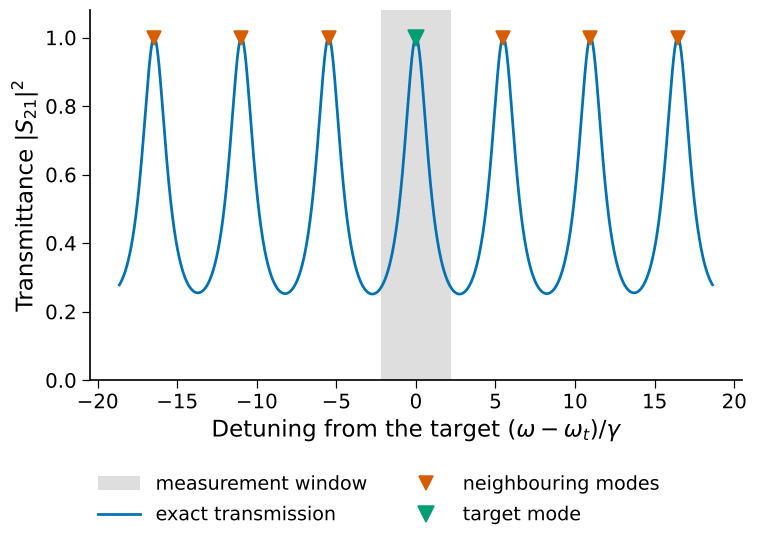

x = 5.48, window half-width = 2.19 linewidths


In [5]:
rep = min(structures, key=lambda s: abs(s["x"] - 5.5))
idx, thk = cavity.fabry_perot(rep["n_high"], rep["periods"])
span = 3.4 * rep["spacing"]
kk = np.linspace(rep["k_target"] - span, rep["k_target"] + span, 6000)
T = np.abs(tmm.smatrix(idx, thk, kk)[:, 0, 1]) ** 2
u = (kk - rep["k_target"]) / rep["gamma"]
h = min(config.WINDOW_A * rep["spacing"], config.WINDOW_B * rep["gamma"]) / rep["gamma"]
comb_u = (np.array(rep["comb_k"]) - rep["k_target"]) / rep["gamma"]
comb_u = comb_u[np.abs(comb_u) < span / rep["gamma"]]

fig, ax = fs.new_figure(17.5, 12.5)
ax.axvspan(-h, h, color=fs.BAND, alpha=0.5, lw=0, label="measurement window")
ax.plot(u, T, color=fs.PALETTE[0], lw=1.8, label="exact transmission")
ax.plot(comb_u[np.abs(comb_u) > 0.5], np.ones(np.sum(np.abs(comb_u) > 0.5)), "v",
        color=fs.PALETTE[1], ms=9, label="neighbouring modes")
ax.plot([0], [1], "v", color=fs.PALETTE[2], ms=10, label="target mode")
ax.set_xlabel(r"Detuning from the target $(\omega-\omega_t)/\gamma$")
ax.set_ylabel(r"Transmittance $|S_{21}|^{2}$")
ax.set_ylim(0, 1.08)
fs.legend_outside(fig, ax)
show(fig, ax, "fig01_spectrum")
print(f"x = {rep['x']:.2f}, window half-width = {h:.2f} linewidths")

### 4.2 The phase law holds to round-off

For every structure the closed-form curve $E(\varphi)$ obtained from the quadratic forms is
compared with direct evaluation of the error functional on 64 phases. The checks also confirm
that the reference is lossless ($\mathbf{P} = N\mathbf{I}$), that the worst-case phase is pinned
to $\psi = 0$ by mirror symmetry, that the fitted single-mode parameters nearly satisfy the
lossless constraint $|\mathbf{d}|^2 = 2\gamma$ although it is not imposed, and that adjacent comb
modes have nearly equal linewidths.

In [6]:
phi = config.phase_grid()
law_dev, curves = [], []
for s in structures:
    idx, thk = cavity.fabry_perot(s["n_high"], s["periods"])
    w = cavity.measurement_window(s["k_target"], s["spacing"], s["gamma"])
    S = tmm.smatrix(idx, thk, w)
    _, S1 = tcmt.single_mode(w, S)
    M, P = ob.quadratic_forms(S1, S)
    direct = ob.sampled_error(S1, S, phi)
    law_dev.append(np.abs(ob.error_curve(M, P, phi) - direct).max() / direct.max())
    curves.append(dict(x=s["x"], A=s["A"], v=s["v"], psi=s["psi"], E=direct.tolist()))

phase_law_summary = dict(
    max_relative_deviation=float(max(law_dev)),
    max_lossless_deviation=float(max(s["lossless"] for s in structures)),
    max_abs_sin_psi=float(max(abs(np.sin(s["psi"])) for s in structures)),
    energy_mismatch_range=[float(min(s["energy_mismatch"] for s in structures)),
                           float(max(s["energy_mismatch"] for s in structures))],
    gamma_ratio_range=[float(min(s["gamma_ratio"] for s in structures)),
                       float(max(s["gamma_ratio"] for s in structures))],
    visibility_range=[float(min(s["v"] for s in structures)),
                      float(max(s["v"] for s in structures))],
    all_fits_converged=bool(all(s["converged"] for s in structures)))
save_json("phase_law.json", dict(summary=phase_law_summary, curves=curves))
for k, val in phase_law_summary.items():
    print(f"{k:<28s} {val}")

max_relative_deviation       1.9615626693756775e-15
max_lossless_deviation       2.240425295785052e-16
max_abs_sin_psi              5.430313358595401e-09
energy_mismatch_range        [-0.0020888987787084368, -7.5397005773192305e-06]
gamma_ratio_range            [1.000987166831201, 1.026022108213856]
visibility_range             [0.151651165089907, 0.8559542800018823]
all_fits_converged           True


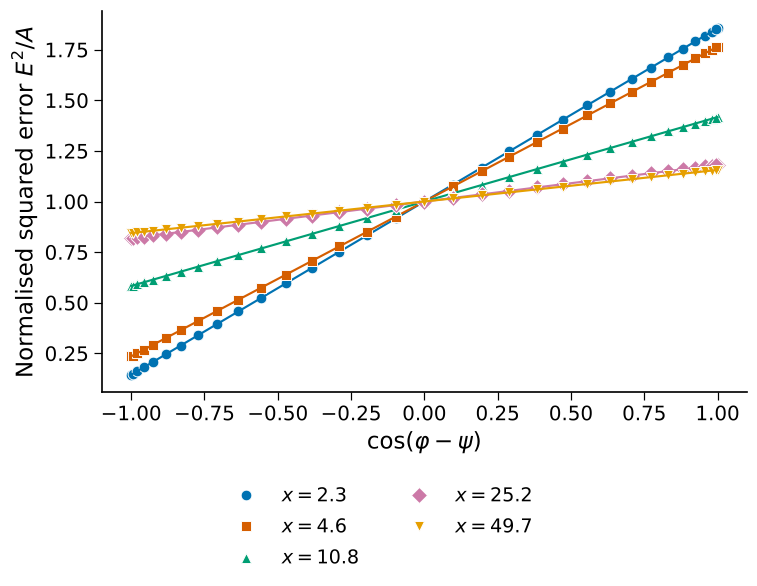

In [7]:
fig, ax = fs.new_figure(17.5, 13.5)
c = np.linspace(-1, 1, 100)
picks = [curves[i] for i in np.linspace(0, len(curves) - 1, 5).round().astype(int)]
for k, cv in enumerate(picks):
    cos_shift = np.cos(phi - cv["psi"])
    ax.plot(cos_shift, np.array(cv["E"]) ** 2 / cv["A"], fs.MARKERS[k], ls="none",
            color=fs.PALETTE[k], mec="white", mew=0.6,
            label=rf"$x = {cv['x']:.1f}$")
    ax.plot(c, 1 + cv["v"] * c, "-", color=fs.PALETTE[k], lw=1.4)
ax.set_xlabel(r"$\cos(\varphi-\psi)$")
ax.set_ylabel(r"Normalised squared error $E^{2}/A$")
fs.legend_outside(fig, ax)
show(fig, ax, "fig02_phase_law")

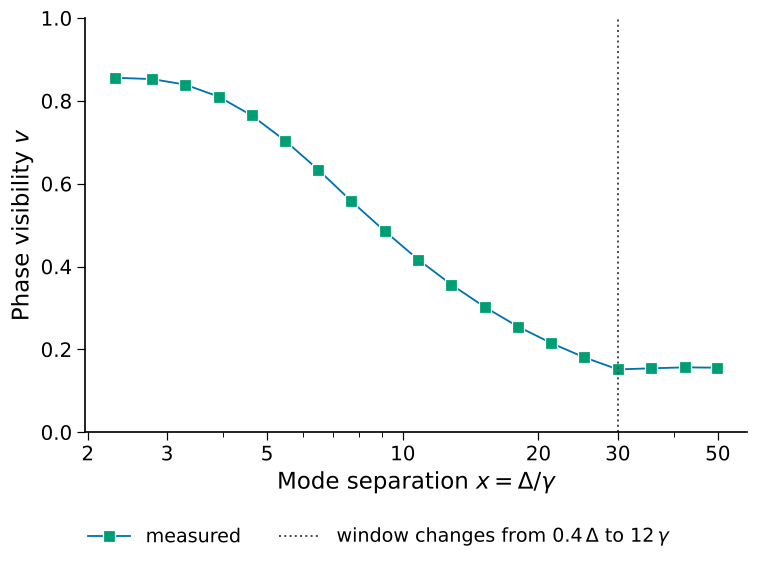

visibility falls from 0.856 at x = 2.30 to 0.152 at x = 30.02; beyond it stays within 0.152 to 0.157


In [8]:
x_all = np.array([s["x"] for s in structures])
v_all = np.array([s["v"] for s in structures])
x_switch = config.WINDOW_B / config.WINDOW_A     # window half-width changes from 0.4 D to 12 g

fig, ax = fs.new_figure(17.5, 13.0)
ax.plot(x_all, v_all, "s-", color=fs.PALETTE[0], lw=1.2, mfc=fs.PALETTE[2], mec="white",
        mew=0.8, ms=8, label="measured")
ax.axvline(x_switch, color=fs.GREY, ls=":", lw=1.3,
           label=r"window changes from $0.4\,\Delta$ to $12\,\gamma$")
fs.log_axis(ax, "x", [2, 3, 5, 10, 20, 30, 50])
ax.set_ylim(0, 1)
ax.set_xlabel(r"Mode separation $x = \Delta/\gamma$")
ax.set_ylabel(r"Phase visibility $v$")
fs.legend_outside(fig, ax)
show(fig, ax, "fig03_visibility")
print(f"visibility falls from {v_all[0]:.3f} at x = {x_all[0]:.2f} to {v_all.min():.3f} at "
      f"x = {x_all[np.argmin(v_all)]:.2f}; beyond it stays within "
      f"{v_all[np.argmin(v_all):].min():.3f} to {v_all[np.argmin(v_all):].max():.3f}")

## 5. The worst-case criterion

### 5.1 Model selection and generalisation

Polynomials of degree one to three in $\ln x$ are compared. Degree one is a pure power law and
cannot describe a rise followed by a fall. The selected degree is the one with the smallest
Bayesian information criterion; leave-one-structure-out cross-validation is reported for each
degree as an independent check against over-fitting.

In [9]:
e_all = np.array([s["e_max"] for s in structures])
selection = criterion.model_selection(x_all, e_all)
degree = min(selection, key=lambda r: r["bic"])["degree"]
coef = criterion.fit(x_all, e_all, degree)
loo_pred = criterion.leave_one_out(x_all, e_all, degree)
loo_ratio = np.maximum(loo_pred / e_all, e_all / loo_pred)

# for comparison only: a random split over (structure, phase) rows shares every structure
rng = config.rng("row-split")
rows_x = np.repeat(x_all, len(phi))
perm = rng.permutation(len(rows_x))
train, test = perm[:int(0.7 * len(perm))], perm[int(0.7 * len(perm)):]
shared = len(set(np.round(rows_x[train], 9)) & set(np.round(rows_x[test], 9)))

for r in selection:
    print(f"degree {r['degree']}:  RSS = {r['rss']:.4f}   AIC = {r['aic']:7.2f}"
          f"   BIC = {r['bic']:7.2f}   leave-one-out discrepancy = {r['loo']:.3f}")
print(f"\nselected degree {degree}; coefficients (highest power first) {np.round(coef, 4)}")
print(f"leave-one-structure-out: median {np.median(loo_ratio):.3f}, worst {loo_ratio.max():.3f}")
print(f"a random 70/30 row split would share {shared} of {len(x_all)} structures "
      f"between training and test sets")

degree 1:  RSS = 1.6444   AIC =   13.43   BIC =   16.26   leave-one-out discrepancy = 1.284
degree 2:  RSS = 0.0531   AIC =  -49.79   BIC =  -46.02   leave-one-out discrepancy = 1.025
degree 3:  RSS = 0.0458   AIC =  -50.62   BIC =  -45.90   leave-one-out discrepancy = 1.050

selected degree 2; coefficients (highest power first) [-0.3731  1.0693 -3.7333]
leave-one-structure-out: median 1.025, worst 1.194
a random 70/30 row split would share 19 of 19 structures between training and test sets


### 5.2 Boundaries and their uncertainty

The 5% and 1% boundaries are the crossings of the fitted criterion with those levels. Their
95% intervals come from 1000 resamples of the 19 structures; the fraction of resamples in which
the fitted peak exceeds 5% is reported because the 5% window exists only when it does.

In [10]:
x_peak, e_peak = criterion.peak(coef)
cross5 = [v for v in criterion.crossings(coef, 0.05) if v > 1]
cross1 = [v for v in criterion.crossings(coef, 0.01) if v > x_peak]
slope50 = criterion.log_slope(coef, 50.0)
boot = criterion.bootstrap(x_all, e_all, degree, config.BOOTSTRAP_RESAMPLES,
                           config.rng("criterion-bootstrap"))
ci = {k: criterion.interval(v, config.CONFIDENCE) for k, v in boot.items()}
window_exists = float(np.mean(np.isfinite(boot["lo_0.05"])))

criterion_result = dict(
    degree=degree, coef=coef.tolist(), selection=selection,
    loo_median=float(np.median(loo_ratio)), loo_worst=float(loo_ratio.max()),
    loo_ratios=loo_ratio.tolist(), row_split_shared=int(shared),
    peak_x=x_peak, peak_e=e_peak, ci_peak_x=ci["peak_x"], ci_peak_e=ci["peak_e"],
    cross5=cross5, ci_cross5_lo=ci["lo_0.05"], ci_cross5_hi=ci["hi_0.05"],
    cross1=cross1[0], ci_cross1=ci["hi_0.01"], window5_fraction=window_exists,
    slope50=slope50, ci_slope50=ci["slope"])
save_json("criterion.json", criterion_result)

print(f"peak {100 * e_peak:.2f} % at x = {x_peak:.2f}  "
      f"(95% CI {np.round(ci['peak_x'], 2)}, {np.round(100 * np.array(ci['peak_e']), 2)} %)")
print(f"5% crossings {np.round(cross5, 2)}  lower CI {np.round(ci['lo_0.05'], 2)}  "
      f"upper CI {np.round(ci['hi_0.05'], 2)}  (window present in {100 * window_exists:.1f}% of resamples)")
print(f"1% boundary {cross1[0]:.2f}  CI {np.round(ci['hi_0.01'], 2)}")
print(f"local exponent at x = 50: {slope50:.2f}  CI {np.round(ci['slope'], 2)}")

peak 5.14 % at x = 4.19  (95% CI [3.73 4.52], [5.05 5.23] %)
5% crossings [3.18 5.53]  lower CI [2.78 3.53]  upper CI [4.78 6.16]  (window present in 99.5% of resamples)
1% boundary 34.07  CI [32.99 37.04]
local exponent at x = 50: -1.85  CI [-1.94 -1.62]


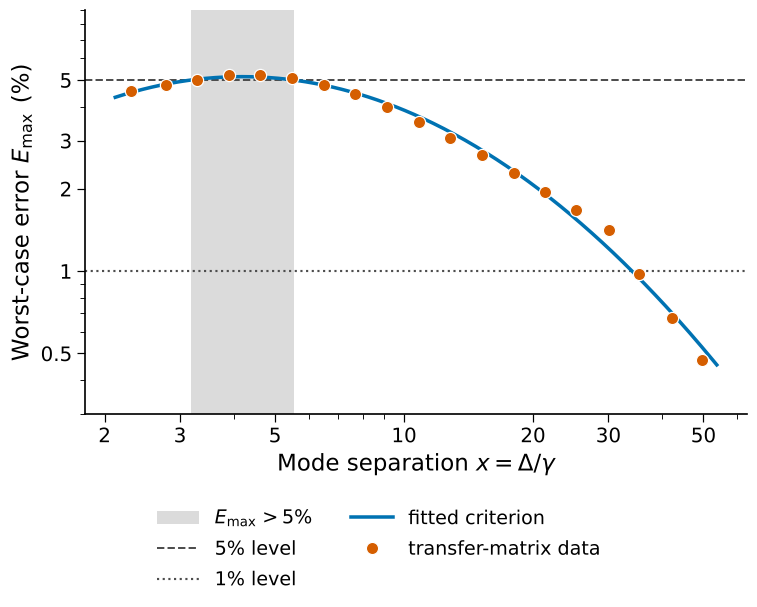

In [11]:
fig, ax = fs.new_figure(17.5, 14.0)
xx = np.geomspace(x_all.min() * 0.92, x_all.max() * 1.08, 400)
ax.axvspan(cross5[0], cross5[1], color=fs.BAND, alpha=0.55, lw=0,
           label=r"$E_{\max} > 5\%$")
ax.axhline(5.0, color=fs.GREY, ls="--", lw=1.3, label="5% level")
ax.axhline(1.0, color=fs.GREY, ls=":", lw=1.4, label="1% level")
ax.plot(xx, 100 * criterion.predict(coef, xx), "-", color=fs.PALETTE[0], lw=2.3,
        label="fitted criterion")
ax.plot(x_all, 100 * e_all, "o", color=fs.PALETTE[1], mec="white", mew=0.8, ms=8,
        label="transfer-matrix data")
fs.log_axis(ax, "x", [2, 3, 5, 10, 20, 30, 50])
fs.log_axis(ax, "y", [0.5, 1, 2, 3, 5])
ax.set_ylim(0.3, 9)
ax.set_xlabel(r"Mode separation $x = \Delta/\gamma$")
ax.set_ylabel(r"Worst-case error $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig04_criterion")

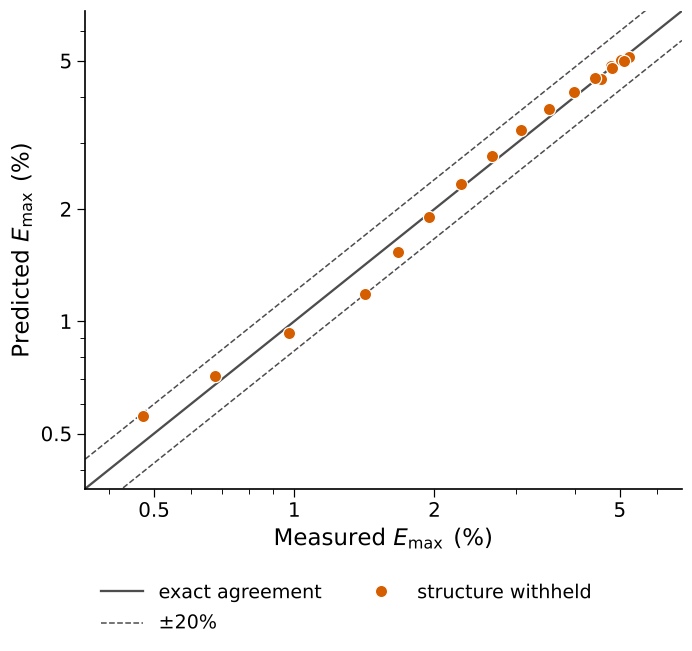

In [12]:
lim = [100 * min(e_all.min(), loo_pred.min()) * 0.75, 100 * max(e_all.max(), loo_pred.max()) * 1.3]
fig, ax = fs.new_figure(16.0, 15.0)
ax.plot(lim, lim, "-", color=fs.GREY, lw=1.5, label="exact agreement")
ax.plot(lim, [1.2 * v for v in lim], "--", color=fs.GREY, lw=1.0, label=r"$\pm 20\%$")
ax.plot(lim, [v / 1.2 for v in lim], "--", color=fs.GREY, lw=1.0)
ax.plot(100 * e_all, 100 * loo_pred, "o", color=fs.PALETTE[1], mec="white", mew=0.8, ms=8,
        label="structure withheld")
fs.log_axis(ax, "x", [0.5, 1, 2, 5])
fs.log_axis(ax, "y", [0.5, 1, 2, 5])
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel(r"Measured $E_{\max}$ (%)")
ax.set_ylabel(r"Predicted $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig05_leave_one_out")

### 5.3 Tail strength

Section 1.4 predicts $E_{\max} \approx c\,\tau$ on the falling branch of the criterion, where the
neighbours are far from the window. The tail strength is computed from the measured comb
(positions and linewidths of all detected modes), independently of the fit.

In [13]:
tau_all = np.array([s["tau"] for s in structures])
branch = x_all > x_peak
c_ratio = e_all / tau_all
c_cav = float(np.exp(np.mean(np.log(c_ratio[branch]))))
tail = dict(c=c_cav, ratio_range=[float(c_ratio[branch].min()), float(c_ratio[branch].max())],
            n_branch=int(branch.sum()),
            spearman=float(spearmanr(tau_all[branch], e_all[branch])[0]))
save_json("tail_strength_cavity.json", tail)
print(f"falling branch (x > {x_peak:.2f}, {branch.sum()} structures): "
      f"E_max / tau = {c_cav:.3f} (geometric mean), range "
      f"{np.round(tail['ratio_range'], 3)}; Spearman {tail['spearman']:.3f}")

falling branch (x > 4.19, 15 structures): E_max / tau = 0.131 (geometric mean), range [0.097 0.157]; Spearman 0.996


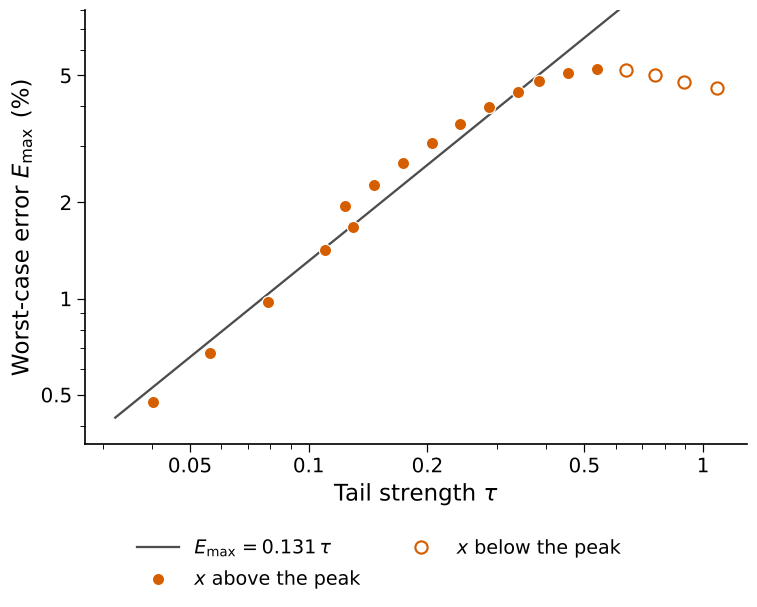

In [14]:
fig, ax = fs.new_figure(17.5, 14.0)
tt = np.geomspace(tau_all[branch].min() * 0.8, tau_all[branch].max() * 1.25, 100)
ax.plot(tt, 100 * c_cav * tt, "-", color=fs.GREY, lw=1.5, label=rf"$E_{{\max}} = {c_cav:.3f}\,\tau$")
ax.plot(tau_all[branch], 100 * e_all[branch], "o", color=fs.PALETTE[1], mec="white", mew=0.8,
        ms=8, label=r"$x$ above the peak")
ax.plot(tau_all[~branch], 100 * e_all[~branch], "o", mfc="white", mec=fs.PALETTE[1], mew=1.4,
        ms=8, label=r"$x$ below the peak")
fs.log_axis(ax, "x", [0.05, 0.1, 0.2, 0.5, 1])
fs.log_axis(ax, "y", [0.5, 1, 2, 5])
ax.set_ylim(0.35, 8)
ax.set_xlabel(r"Tail strength $\tau$")
ax.set_ylabel(r"Worst-case error $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig06_tail_strength")

### 5.4 Sensitivity to the measurement window

The window is part of the definition of $E$. Here every structure is re-measured with four
alternative windows: narrower and wider versions of the baseline rule, a window that always
scales with the mode spacing ($h = 0.4\Delta$), and the baseline window sampled with half and
twice as many points. The criterion is refitted for each and the boundaries are compared.

In [15]:
variants = {
    "baseline  min(0.40 D, 12 g)": dict(a=0.40, b=12.0, n=1600),
    "narrow    min(0.30 D,  8 g)": dict(a=0.30, b=8.0, n=1600),
    "wide      min(0.45 D, 16 g)": dict(a=0.45, b=16.0, n=1600),
    "spacing   0.40 D": dict(a=0.40, b=np.inf, n=1600),
    "baseline, 800 points": dict(a=0.40, b=12.0, n=800),
    "baseline, 3200 points": dict(a=0.40, b=12.0, n=3200),
}
sensitivity = {}
for label, var in variants.items():
    e_var, tau_var = [], []
    for s in structures:
        idx, thk = cavity.fabry_perot(s["n_high"], s["periods"])
        w = cavity.measurement_window(s["k_target"], s["spacing"], s["gamma"],
                                      a=var["a"], b=var["b"], n_points=var["n"])
        S = tmm.smatrix(idx, thk, w)
        _, S1 = tcmt.single_mode(w, S)
        e_var.append(ob.worst_case(*ob.quadratic_forms(S1, S)))
        pos, wid = np.array(s["comb_k"]), np.array(s["comb_gamma"])
        m = np.arange(len(pos)) != s["target_index"]
        tau_var.append(np.sum(2 * wid[m] * 0.5 * (w[-1] - w[0]) / (pos[m] - s["k_target"]) ** 2))
    e_var, tau_var = np.array(e_var), np.array(tau_var)
    c_var = criterion.fit(x_all, e_var, degree)
    px, pe = criterion.peak(c_var)
    c5 = [v for v in criterion.crossings(c_var, 0.05) if v > 1]
    c1 = [v for v in criterion.crossings(c_var, 0.01) if v > px]
    br = x_all > px
    sensitivity[label] = dict(
        a=var["a"], b=None if np.isinf(var["b"]) else var["b"], n=var["n"],
        e_max=e_var.tolist(), peak_x=px, peak_e=pe, cross5=c5,
        cross1=c1[0] if c1 else None, slope50=criterion.log_slope(c_var, 50.0),
        c_tail=float(np.exp(np.mean(np.log(e_var[br] / tau_var[br])))),
        c_tail_range=[float((e_var[br] / tau_var[br]).min()),
                      float((e_var[br] / tau_var[br]).max())])
    r = sensitivity[label]
    print(f"{label:<28s} peak {100 * pe:5.2f}% at {px:5.2f}  5%: {np.round(c5, 2)}  "
          f"1%: {r['cross1'] if r['cross1'] is None else round(r['cross1'], 1)}  "
          f"slope(50) {r['slope50']:5.2f}  E/tau {r['c_tail']:.3f}")
save_json("window_sensitivity.json", sensitivity)

baseline  min(0.40 D, 12 g)  peak  5.14% at  4.19  5%: [3.18 5.53]  1%: 34.1  slope(50) -1.85  E/tau 0.131


narrow    min(0.30 D,  8 g)  peak  3.01% at  5.40  5%: []  1%: 25.8  slope(50) -2.00  E/tau 0.120


wide      min(0.45 D, 16 g)  peak  6.43% at  3.47  5%: [1.4  8.58]  1%: 40.7  slope(50) -1.64  E/tau 0.135


spacing   0.40 D             peak  5.06% at  3.26  5%: [2.6  4.09]  1%: 41.3  slope(50) -1.37  E/tau 0.124


baseline, 800 points         peak  5.15% at  4.19  5%: [3.16 5.56]  1%: 34.1  slope(50) -1.85  E/tau 0.131


baseline, 3200 points        peak  5.14% at  4.19  5%: [3.19 5.51]  1%: 34.1  slope(50) -1.85  E/tau 0.131


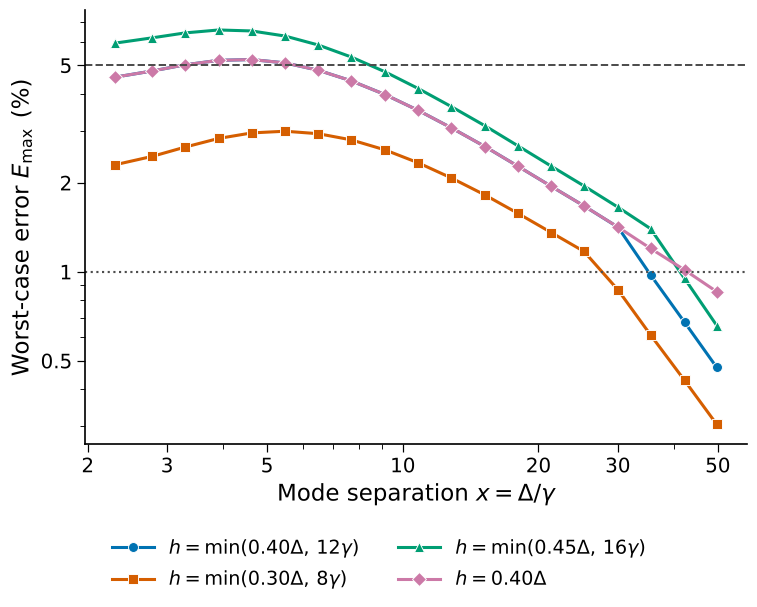

In [16]:
fig, ax = fs.new_figure(17.5, 14.0)
for k, label in enumerate(list(variants)[:4]):
    ax.plot(x_all, 100 * np.array(sensitivity[label]["e_max"]), "-" + fs.MARKERS[k],
            color=fs.PALETTE[k], ms=6.5, mec="white", mew=0.6,
            label={0: r"$h=\min(0.40\Delta,\,12\gamma)$", 1: r"$h=\min(0.30\Delta,\,8\gamma)$",
                   2: r"$h=\min(0.45\Delta,\,16\gamma)$", 3: r"$h=0.40\Delta$"}[k])
ax.axhline(1.0, color=fs.GREY, ls=":", lw=1.4)
ax.axhline(5.0, color=fs.GREY, ls="--", lw=1.3)
fs.log_axis(ax, "x", [2, 3, 5, 10, 20, 30, 50])
fs.log_axis(ax, "y", [0.2, 0.5, 1, 2, 5])
ax.set_xlabel(r"Mode separation $x = \Delta/\gamma$")
ax.set_ylabel(r"Worst-case error $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig07_window")

## 6. Mechanism: recovery by multimode models

If the single-mode error is the truncated tail of neighbouring modes, adding those modes to the
model on the *same* window must remove it. Each structure is refitted with $M = 1, 2, 3, 5$
modes: the target plus the $M-1$ comb modes nearest to it. The neighbours lie outside the
window, so their positions and linewidths are fixed at the values measured from the spectrum
and only their coupling vectors are fitted, together with the target pole, the background and
the reference-plane phase. The error metric and window are those of Figure 4.

For comparison the single-mode model is also refitted with a background that varies linearly
or quadratically across the window, $\mathbf{C}(\omega) = \sum_k \mathbf{C}_k u^k$ with
$u = (\omega-\omega_{\mathrm{ref}})/h$. This extension is phenomenological: it adds no pole and
does not respect the lossless constraints, but it tests directly whether the error comes from the
assumption of a constant background.

In [17]:
mode_counts = (1, 2, 3, 5)
multimode = []
t0 = time.time()
for s in structures:
    idx, thk = cavity.fabry_perot(s["n_high"], s["periods"])
    w = cavity.measurement_window(s["k_target"], s["spacing"], s["gamma"])
    S = tmm.smatrix(idx, thk, w)
    pos, wid = np.array(s["comb_k"]), np.array(s["comb_gamma"])
    order = np.argsort(np.abs(pos - s["k_target"]))

    def exact_at(k, idx=idx, thk=thk):
        return tmm.smatrix(idx, thk, np.array([k]))[0]

    row = dict(x=s["x"])
    family = tcmt.single_mode_family(w, S, max_order=2)
    previous = family[0][0]
    row["M1"] = ob.worst_case(*ob.quadratic_forms(family[0][1], S))
    for m in mode_counts[1:]:
        sel = order[:m]                    # the target comes first, then by distance
        poles = [(pos[j], wid[j]) for j in sel]
        free = [j == s["target_index"] for j in sel]
        previous, Sm = tcmt.best_fit(w, S, poles, free, S_at=exact_at, starts=[previous])
        row[f"M{m}"] = ob.worst_case(*ob.quadratic_forms(Sm, S))
    for order_bg in (1, 2):
        row[f"B{order_bg}"] = ob.worst_case(*ob.quadratic_forms(family[order_bg][1], S))
    multimode.append(row)
    print(f"x = {row['x']:6.2f}   " + "   ".join(f"M={m}: {100 * row[f'M{m}']:7.4f}%"
                                              for m in mode_counts)
          + f"   linear bg: {100 * row['B1']:7.4f}%   quadratic bg: {100 * row['B2']:7.4f}%")
save_json("multimode.json", multimode)
gain3 = np.array([r["M1"] / r["M3"] for r in multimode])
gain5 = np.array([r["M1"] / r["M5"] for r in multimode])
print(f"\nadding both adjacent modes reduces E_max by {gain3.min():.0f}x to {gain3.max():.0f}x; "
      f"adding two on each side by {gain5.min():.0f}x to {gain5.max():.0f}x")
print(f"largest error with a linear background {100 * max(r['B1'] for r in multimode):.2f}%, "
      f"with a quadratic background {100 * max(r['B2'] for r in multimode):.2f}%  "
      f"({time.time() - t0:.0f} s)")

x =   2.30   M=1:  4.5607%   M=2:  2.6301%   M=3:  0.3872%   M=5:  0.0103%   linear bg:  1.0466%   quadratic bg:  0.2797%


x =   2.78   M=1:  4.7848%   M=2:  2.6813%   M=3:  0.2971%   M=5:  0.0066%   linear bg:  1.0178%   quadratic bg:  0.2702%


x =   3.29   M=1:  5.0191%   M=2:  2.7127%   M=3:  0.2412%   M=5:  0.0051%   linear bg:  0.9749%   quadratic bg:  0.2560%


x =   3.90   M=1:  5.1981%   M=2:  2.6847%   M=3:  0.2014%   M=5:  0.0034%   linear bg:  0.9144%   quadratic bg:  0.2363%


x =   4.62   M=1:  5.2289%   M=2:  2.5716%   M=3:  0.1698%   M=5:  0.0046%   linear bg:  0.8357%   quadratic bg:  0.2109%


x =   5.48   M=1:  5.0946%   M=2:  2.3899%   M=3:  0.1444%   M=5:  0.0050%   linear bg:  0.7481%   quadratic bg:  0.1835%


... (9 outputs left out)

x =  30.02   M=1:  1.4159%   M=2:  0.5707%   M=3:  0.0303%   M=5:  0.0018%   linear bg:  0.1613%   quadratic bg:  0.0567%


x =  35.45   M=1:  0.9766%   M=2:  0.3364%   M=3:  0.0151%   M=5:  0.0008%   linear bg:  0.0782%   quadratic bg:  0.0288%


x =  42.18   M=1:  0.6751%   M=2:  0.1969%   M=3:  0.0074%   M=5:  0.0003%   linear bg:  0.0376%   quadratic bg:  0.0143%


x =  49.73   M=1:  0.4743%   M=2:  0.1179%   M=3:  0.0038%   M=5:  0.0001%   linear bg:  0.0189%   quadratic bg:  0.0074%

adding both adjacent modes reduces E_max by 12x to 126x; adding two on each side by 444x to 3404x
largest error with a linear background 1.05%, with a quadratic background 0.28%  (71 s)


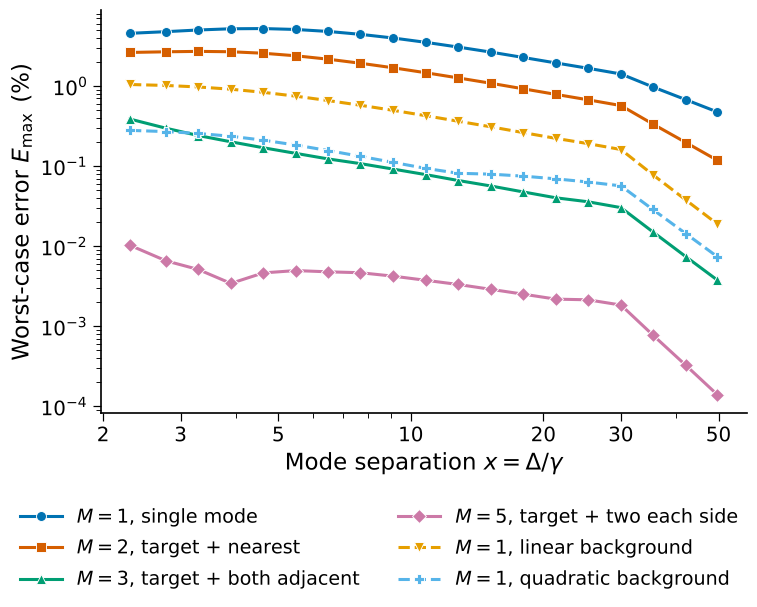

In [18]:
fig, ax = fs.new_figure(17.5, 14.0)
labels = {1: "single mode", 2: "target + nearest", 3: "target + both adjacent",
          5: "target + two each side"}
xs = [r["x"] for r in multimode]
for k, m in enumerate(mode_counts):
    ax.plot(xs, [100 * r[f"M{m}"] for r in multimode], "-" + fs.MARKERS[k],
            color=fs.PALETTE[k], ms=6.5, mec="white", mew=0.6,
            label=rf"$M={m}$, {labels[m]}")
ax.plot(xs, [100 * r["B1"] for r in multimode], "--" + fs.MARKERS[4], color=fs.PALETTE[4],
        ms=6.5, mec="white", mew=0.6, label=r"$M=1$, linear background")
ax.plot(xs, [100 * r["B2"] for r in multimode], "--" + fs.MARKERS[5], color=fs.PALETTE[5],
        ms=6.5, mec="white", mew=0.6, label=r"$M=1$, quadratic background")
fs.log_axis(ax, "x", [2, 3, 5, 10, 20, 30, 50])
fs.log_axis(ax, "y")
ax.set_xlabel(r"Mode separation $x = \Delta/\gamma$")
ax.set_ylabel(r"Worst-case error $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig08_multimode")

## 7. Separation, not quality factor, sets the error

The finesse is fixed by the mirrors and the quality factor by the cavity length. For five target
separations the mirror is fixed and the cavity length is varied from 10 to 160 half-waves, which
changes $Q$ by more than an order of magnitude at nearly constant $x$. The separation drifts
slightly with length; its effect is removed with the local slope of the criterion before the
remaining variation is attributed to $Q$.

In [19]:
q_targets = (4.5, 8.8, 14.0, 20.7, 30.0)
lengths = (10, 20, 40, 80, 160)
q_records = []
for target in q_targets:
    periods, n_high = cavity.design_for_separation(target, table)
    for m in lengths:
        idx, thk = cavity.fabry_perot(n_high, periods, m_halfwave=m)
        kt, kn, gt, gn = cavity.target_pair(idx, thk, k_c)
        w = cavity.measurement_window(kt, abs(kn - kt), gt)
        S = tmm.smatrix(idx, thk, w)
        _, S1 = tcmt.single_mode(w, S)
        M, P = ob.quadratic_forms(S1, S)
        A, v, psi = ob.phase_law(M, P)
        q_records.append(dict(target=target, m=m, x=float(abs(kn - kt) / gt),
                              Q=float(kt / (2 * gt)), e_max=float(np.sqrt(A * (1 + v))), v=float(v)))

q_summary = []
for target in q_targets:
    g = [r for r in q_records if r["target"] == target]
    xq = np.array([r["x"] for r in g])
    eq = np.array([r["e_max"] for r in g])
    Qq = np.array([r["Q"] for r in g])
    corrected = np.log(eq) - (np.log(criterion.predict(coef, xq))
                              - np.log(criterion.predict(coef, xq[0])))
    slope_q = np.polyfit(np.log(Qq), corrected, 1)[0]
    q_summary.append(dict(
        target=target, Q_ratio=float(Qq.max() / Qq.min()),
        x_drift=float((xq.max() - xq.min()) / xq.min()),
        raw_spread=float(eq.max() / eq.min() - 1),
        corrected_spread=float(np.exp(corrected.max() - corrected.min()) - 1),
        dlnE_dlnQ=float(slope_q), dlnE_dlnx=criterion.log_slope(coef, xq.mean()),
        v_spread=float(max(r["v"] for r in g) - min(r["v"] for r in g))))
    r = q_summary[-1]
    print(f"x ~ {target:5.1f}: Q x{r['Q_ratio']:5.1f}, x drift {100 * r['x_drift']:.2f}%, "
          f"E spread {100 * r['raw_spread']:.2f}% -> {100 * r['corrected_spread']:.2f}% after "
          f"drift correction; dlnE/dlnQ = {r['dlnE_dlnQ']:+.4f}, dlnE/dlnx = {r['dlnE_dlnx']:+.3f}, "
          f"v varies by {r['v_spread']:.4f}")
save_json("quality_factor.json", dict(records=q_records, summary=q_summary))

x ~   4.5: Q x 14.1, x drift 0.95%, E spread 0.59% -> 0.55% after drift correction; dlnE/dlnQ = -0.0020, dlnE/dlnx = -0.052, v varies by 0.0003
x ~   8.8: Q x 13.2, x drift 1.32%, E spread 3.35% -> 2.61% after drift correction; dlnE/dlnQ = -0.0091, dlnE/dlnx = -0.552, v varies by 0.0006
x ~  14.0: Q x 13.3, x drift 0.63%, E spread 4.24% -> 3.85% after drift correction; dlnE/dlnQ = -0.0131, dlnE/dlnx = -0.898, v varies by 0.0007
x ~  20.7: Q x 13.5, x drift 0.31%, E spread 4.74% -> 4.36% after drift correction; dlnE/dlnQ = -0.0148, dlnE/dlnx = -1.189, v varies by 0.0011
x ~  30.0: Q x 12.9, x drift 0.45%, E spread 9.44% -> 8.73% after drift correction; dlnE/dlnQ = -0.0301, dlnE/dlnx = -1.465, v varies by 0.0014


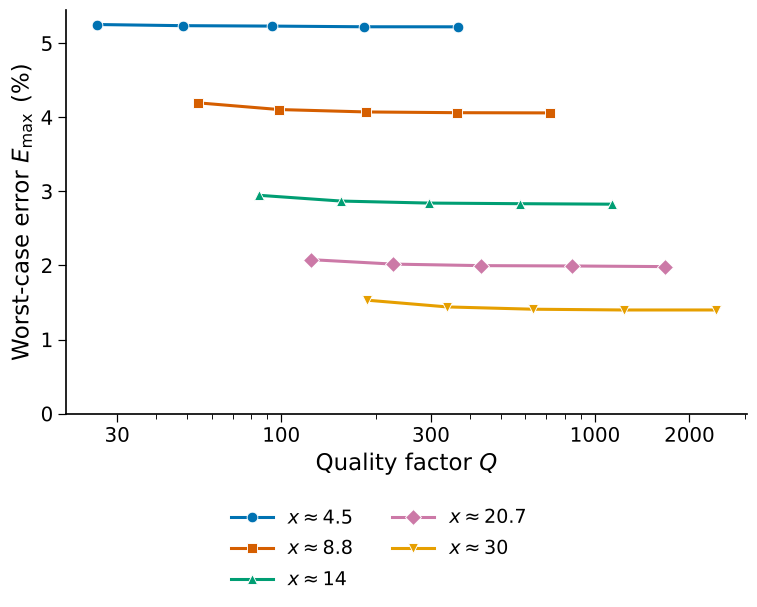

In [20]:
fig, ax = fs.new_figure(17.5, 14.0)
for k, target in enumerate(q_targets):
    g = sorted([r for r in q_records if r["target"] == target], key=lambda r: r["Q"])
    ax.plot([r["Q"] for r in g], [100 * r["e_max"] for r in g], "-" + fs.MARKERS[k],
            color=fs.PALETTE[k], ms=7, mec="white", mew=0.6, label=rf"$x \approx {target:g}$")
fs.log_axis(ax, "x", [30, 100, 300, 1000, 2000])
ax.set_ylim(0, None)
ax.set_xlabel(r"Quality factor $Q$")
ax.set_ylabel(r"Worst-case error $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig09_quality_factor")

## 8. Transfer to a grating platform

Guided-mode resonances of binary gratings provide a second, unrelated platform. The scan covers
54 geometries: high-index permittivity 4, 5, 6.5, 8, 10 and 12, fill factors 0.35, 0.5 and 0.65,
and thicknesses 0.5, 0.8 and 1.1 periods, with air on both sides. For each geometry the
resonance catalogue (positions and linewidths of every activity peak between $f = 0.30$ and the
diffraction threshold) is built first. Targets are the resolved resonances with
$0.42 \le f \le 0.95$ and $2 \le x \le 60$ whose measurement window lies entirely below the
diffraction threshold $f = 1$, where $x$ is the distance to the nearest catalogued resonance in
units of the target linewidth.

Each target is measured with exactly the pipeline of the cavity platform: the same window rule,
the same single-mode fit and the same closed-form worst case. In addition, each is refitted with
the nearest two and four catalogued neighbours ($M = 3, 5$) and with linear and quadratic
backgrounds, and its tail strength $\tau$ is computed from the catalogue. The cell takes about
an hour.

In [21]:
geometries = [dict(eps_high=e, fill=fi, thickness=th)
              for e in (4.0, 5.0, 6.5, 8.0, 10.0, 12.0)
              for fi in (0.35, 0.5, 0.65)
              for th in (0.5, 0.8, 1.1)]
grating = []
t0 = time.time()
for g in geometries:
    cat = fmm.resonances(g)
    if len(cat) < 2:
        continue
    pos = np.array([c["f"] for c in cat])
    wid = np.array([c["gamma"] for c in cat])

    def exact_at(f0, g=g):
        return fmm.smatrix([f0], **g)[0]

    for j, c in enumerate(cat):
        others = np.arange(len(pos)) != j
        spacing = np.min(np.abs(pos[others] - c["f"]))
        x = spacing / c["gamma"]
        if not (c["resolved"] and 0.42 <= c["f"] <= 0.95 and 2.0 <= x <= 60.0):
            continue
        w = cavity.measurement_window(c["f"], spacing, c["gamma"])
        if w[-1] >= 1.0:                   # window must stay below the diffraction threshold
            continue
        S = fmm.smatrix(w, **g)
        h = 0.5 * (w[-1] - w[0])
        family = tcmt.single_mode_family(w, S, max_order=2)
        p1, S1 = family[0]
        M, P = ob.quadratic_forms(S1, S)
        A, v, psi = ob.phase_law(M, P)
        rec = dict(**g, f=c["f"], gamma=c["gamma"], spacing=float(spacing), x=float(x),
                   Q=float(c["f"] / (2 * c["gamma"])),
                   tau=float(np.sum(2 * wid[others] * h / (pos[others] - c["f"]) ** 2)),
                   E1=float(np.sqrt(A * (1 + v))), v=float(v), psi=float(psi),
                   lossless=ob.losslessness(P),
                   pole_shift=float(abs(p1["poles"][0][0] - c["f"]) / c["gamma"]))
        order = np.argsort(np.abs(pos - c["f"]))
        previous = p1
        for m in (3, 5):
            sel = order[:m]                # the target comes first, then by distance
            poles = [(pos[k], wid[k]) for k in sel]
            free = [k == j for k in sel]
            previous, Sm = tcmt.best_fit(w, S, poles, free, S_at=exact_at, starts=[previous])
            rec[f"E{m}"] = ob.worst_case(*ob.quadratic_forms(Sm, S))
        for order_bg in (1, 2):
            rec[f"B{order_bg}"] = ob.worst_case(*ob.quadratic_forms(family[order_bg][1], S))
        grating.append(rec)
print(f"{len(grating)} grating resonances measured in {time.time() - t0:.0f} s")
save_json("grating.json", grating)

88 grating resonances measured in 3927 s


### 8.1 The phase law and the criterion on the grating platform

In [22]:
xg = np.array([r["x"] for r in grating])
eg = np.array([r["E1"] for r in grating])
taug = np.array([r["tau"] for r in grating])
ratio_g = eg / criterion.predict(coef, xg)
slope_g, _ = np.polyfit(np.log(xg), np.log(eg), 1)

grating_summary = dict(
    n=len(grating), n_geometries=len({(r["eps_high"], r["fill"], r["thickness"]) for r in grating}),
    x_range=[float(xg.min()), float(xg.max())],
    max_lossless=float(max(r["lossless"] for r in grating)),
    max_abs_sin_psi=float(max(abs(np.sin(r["psi"])) for r in grating)),
    pole_left_target=int(sum(r["pole_shift"] > 1 for r in grating)),
    ratio_median=float(np.median(ratio_g)),
    ratio_iqr=[float(np.percentile(ratio_g, 25)), float(np.percentile(ratio_g, 75))],
    ratio_range=[float(ratio_g.min()), float(ratio_g.max())],
    loglog_slope=float(slope_g),
    spearman_x=float(spearmanr(xg, eg)[0]), spearman_tau=float(spearmanr(taug, eg)[0]),
    tail_ratio_median=float(np.median(eg / (c_cav * taug))))
for k, val in grating_summary.items():
    print(f"{k:<20s} {val}")

n                    88
n_geometries         40
x_range              [2.0783572688334675, 59.486968690556395]
max_lossless         1.5692666896613231e-12
max_abs_sin_psi      1.0079025086491943e-05
pole_left_target     1
ratio_median         2.859597470257766
ratio_iqr            [1.1025311654856, 7.939092905692991]
ratio_range          [0.0002270177747053454, 69.95552517304574]
loglog_slope         0.20082296587416115
spearman_x           0.17658842850206602
spearman_tau         -0.19159240604416897
tail_ratio_median    3.277463747772921


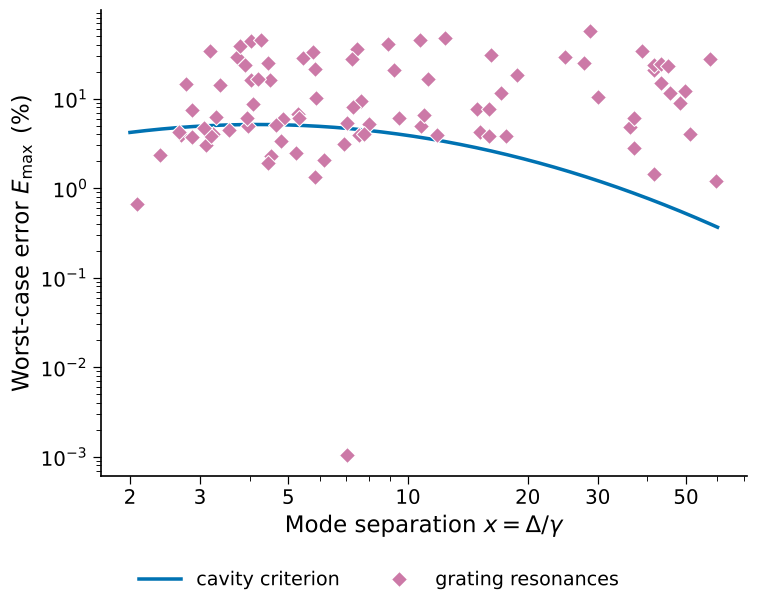

In [23]:
fig, ax = fs.new_figure(17.5, 14.0)
xx = np.geomspace(2.0, 60.0, 300)
ax.plot(xx, 100 * criterion.predict(coef, xx), "-", color=fs.PALETTE[0], lw=2.3,
        label="cavity criterion")
ax.plot(xg, 100 * eg, "D", color=fs.PALETTE[3], mec="white", mew=0.7, ms=7,
        label="grating resonances")
fs.log_axis(ax, "x", [2, 3, 5, 10, 20, 30, 50])
fs.log_axis(ax, "y")
ax.set_xlabel(r"Mode separation $x = \Delta/\gamma$")
ax.set_ylabel(r"Worst-case error $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig10_grating_separation")

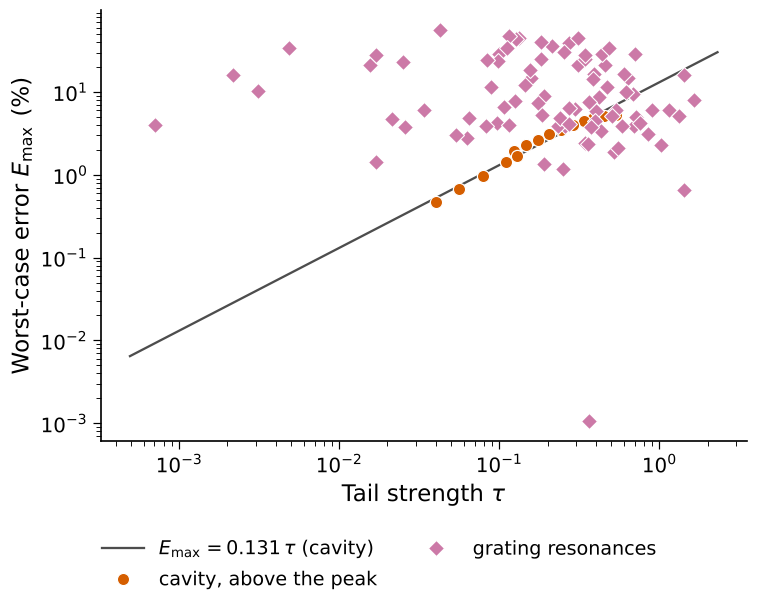

In [24]:
fig, ax = fs.new_figure(17.5, 14.0)
tt = np.geomspace(min(taug.min(), tau_all.min()) * 0.7, max(taug.max(), tau_all.max()) * 1.4, 100)
ax.plot(tt, 100 * c_cav * tt, "-", color=fs.GREY, lw=1.5,
        label=rf"$E_{{\max}} = {c_cav:.3f}\,\tau$ (cavity)")
ax.plot(tau_all[branch], 100 * e_all[branch], "o", color=fs.PALETTE[1], mec="white", mew=0.8,
        ms=8, label="cavity, above the peak")
ax.plot(taug, 100 * eg, "D", color=fs.PALETTE[3], mec="white", mew=0.7, ms=7,
        label="grating resonances")
fs.log_axis(ax, "x")
fs.log_axis(ax, "y")
ax.set_xlabel(r"Tail strength $\tau$")
ax.set_ylabel(r"Worst-case error $E_{\max}$ (%)")
fs.legend_outside(fig, ax)
show(fig, ax, "fig11_grating_tail")

### 8.2 Which model extension restores accuracy on the grating?

The empirical distribution of the worst-case error over all grating resonances is compared for
the single-mode model, the multimode models with catalogued neighbours, and the single-mode
model with a dispersive background.

$M=1$, constant background         median   7.64%   90th percentile  33.92%   below 1%:   2.3%   below 5%:  35.2%
$M=3$, catalogued neighbours       median   1.59%   90th percentile  11.34%   below 1%:  38.6%   below 5%:  77.3%
$M=5$, catalogued neighbours       median   0.50%   90th percentile   7.31%   below 1%:  61.4%   below 5%:  87.5%
$M=1$, linear background           median   3.00%   90th percentile  13.78%   below 1%:   9.1%   below 5%:  67.0%
$M=1$, quadratic background        median   0.55%   90th percentile   5.66%   below 1%:  68.2%   below 5%:  87.5%
resonances with E_max below 1e-3 % (left of the plotted range): {'E1': 0, 'E3': 1, 'E5': 2, 'B1': 1, 'B2': 1}


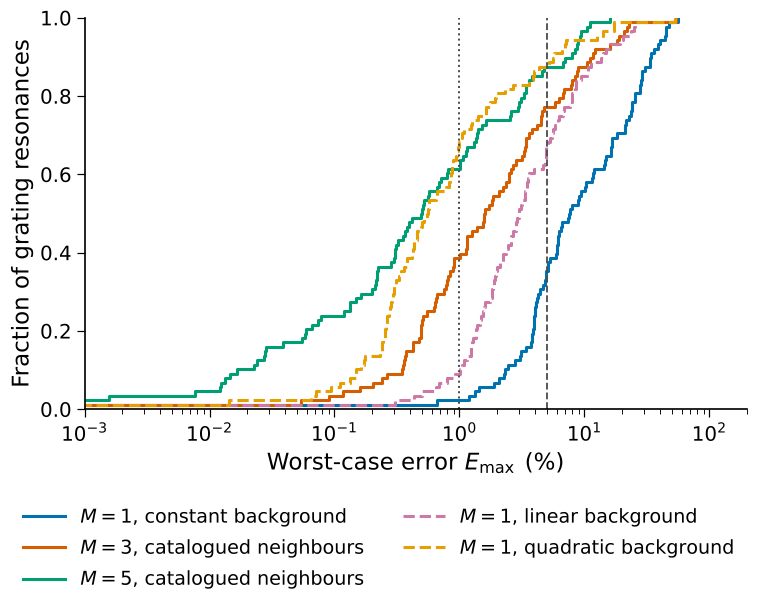

In [25]:
variants_g = [("E1", r"$M=1$, constant background"), ("E3", r"$M=3$, catalogued neighbours"),
              ("E5", r"$M=5$, catalogued neighbours"), ("B1", r"$M=1$, linear background"),
              ("B2", r"$M=1$, quadratic background")]
model_table = {}
for key, label in variants_g:
    vals = np.array([r[key] for r in grating])
    model_table[key] = dict(label=label, median=float(np.median(vals)),
                            p90=float(np.percentile(vals, 90)),
                            below_1=float(np.mean(vals < 0.01)),
                            below_5=float(np.mean(vals < 0.05)))
    t = model_table[key]
    print(f"{label:<34s} median {100 * t['median']:6.2f}%   90th percentile {100 * t['p90']:6.2f}%"
          f"   below 1%: {100 * t['below_1']:5.1f}%   below 5%: {100 * t['below_5']:5.1f}%")
grating_summary["models"] = model_table
save_json("grating_summary.json", grating_summary)

fig, ax = fs.new_figure(17.5, 14.0)
for k, (key, label) in enumerate(variants_g):
    vals = np.sort([100 * r[key] for r in grating])
    ax.step(vals, np.arange(1, len(vals) + 1) / len(vals), where="post",
            color=fs.PALETTE[k], lw=2.0, ls="-" if key[0] == "E" else "--", label=label)
ax.axvline(1.0, color=fs.GREY, ls=":", lw=1.3)
ax.axvline(5.0, color=fs.GREY, ls="--", lw=1.2)
fs.log_axis(ax, "x")
x_floor = 1e-3                                   # per cent; smaller errors are counted, not drawn
ax.set_xlim(x_floor, 200)
ax.set_ylim(0, 1.0)
below_floor = {key: int(sum(100 * r[key] < x_floor for r in grating)) for key, _ in variants_g}
grating_summary["below_plot_floor"] = below_floor
save_json("grating_summary.json", grating_summary)
print("resonances with E_max below 1e-3 % (left of the plotted range):", below_floor)
ax.set_xlabel(r"Worst-case error $E_{\max}$ (%)")
ax.set_ylabel(r"Fraction of grating resonances")
fs.legend_outside(fig, ax)
show(fig, ax, "fig12_grating_models")

## 9. Summary of results

All numbers quoted in the article are collected here from the result files written above.

In [26]:
summary = dict(
    environment=environment,
    validation={c["check"]: c["value"] for c in checks},
    realised=len(structures), unrealised=unrealised,
    x_range=[float(x_all.min()), float(x_all.max())],
    phase_law=phase_law_summary,
    criterion=dict((k, criterion_result[k]) for k in (
        "degree", "coef", "selection", "loo_median", "loo_worst", "row_split_shared",
        "peak_x", "peak_e", "ci_peak_x", "ci_peak_e", "cross5", "ci_cross5_lo", "ci_cross5_hi",
        "cross1", "ci_cross1", "window5_fraction", "slope50", "ci_slope50")),
    tail_cavity=tail,
    window_sensitivity={k: {kk: vv for kk, vv in v.items() if kk != "e_max"}
                        for k, v in sensitivity.items()},
    multimode=dict(gain3=[float(gain3.min()), float(gain3.max())],
                   gain5=[float(gain5.min()), float(gain5.max())],
                   max_M1=float(max(r["M1"] for r in multimode)),
                   max_M2=float(max(r["M2"] for r in multimode)),
                   max_M3=float(max(r["M3"] for r in multimode)),
                   max_M5=float(max(r["M5"] for r in multimode)),
                   max_B1=float(max(r["B1"] for r in multimode)),
                   max_B2=float(max(r["B2"] for r in multimode))),
    quality_factor=q_summary,
    grating=grating_summary,
    runtime_minutes=(time.time() - T_START) / 60.0)
save_json("summary.json", summary)

c = summary["criterion"]
rows = [
    ("Structures realised (cavity)", f"{summary['realised']} of 24, x = {x_all.min():.2f} to {x_all.max():.2f}"),
    ("Phase law, largest deviation", f"{phase_law_summary['max_relative_deviation']:.1e}"),
    ("Worst-case phase |sin psi|", f"{phase_law_summary['max_abs_sin_psi']:.1e}"),
    ("Selected degree (BIC)", f"{c['degree']}"),
    ("Leave-one-structure-out", f"median {c['loo_median']:.3f}, worst {c['loo_worst']:.3f}"),
    ("Peak of E_max", f"{100 * c['peak_e']:.2f}% at x = {c['peak_x']:.2f}"),
    ("5% window", f"[{c['cross5'][0]:.2f}, {c['cross5'][1]:.2f}]"),
    ("1% boundary", f"x = {c['cross1']:.1f}, 95% CI {np.round(c['ci_cross1'], 1).tolist()}"),
    ("Exponent at x = 50", f"{c['slope50']:.2f}"),
    ("E_max / tau (falling branch)", f"{tail['c']:.3f}, range {np.round(tail['ratio_range'], 3).tolist()}"),
    ("Gain from both adjacent modes", f"{gain3.min():.0f}x to {gain3.max():.0f}x"),
    ("Largest E_max, linear background", f"{100 * summary['multimode']['max_B1']:.2f}%"),
    ("Q dependence after drift correction", f"<= {100 * max(r['corrected_spread'] for r in q_summary):.1f}%"),
    ("Grating resonances", f"{grating_summary['n']} in {grating_summary['n_geometries']} geometries"),
    ("Grating / cavity criterion", f"median {grating_summary['ratio_median']:.2f}, "
                                   f"IQR {np.round(grating_summary['ratio_iqr'], 2).tolist()}"),
    ("Grating median E_max: M=1 / M=5 / quadratic bg",
     f"{100 * model_table['E1']['median']:.2f}% / {100 * model_table['E5']['median']:.2f}% / "
     f"{100 * model_table['B2']['median']:.2f}%"),
]
width = max(len(r[0]) for r in rows)
for name, value in rows:
    print(f"{name:<{width}s}  {value}")
print(f"\ntotal run time {summary['runtime_minutes']:.1f} min")

Structures realised (cavity)                    19 of 24, x = 2.30 to 49.73
Phase law, largest deviation                    2.0e-15
Worst-case phase |sin psi|                      5.4e-09
Selected degree (BIC)                           2
Leave-one-structure-out                         median 1.025, worst 1.194
Peak of E_max                                   5.14% at x = 4.19
5% window                                       [3.18, 5.53]
1% boundary                                     x = 34.1, 95% CI [33.0, 37.0]
Exponent at x = 50                              -1.85
E_max / tau (falling branch)                    0.131, range [0.097, 0.157]
Gain from both adjacent modes                   12x to 126x
Largest E_max, linear background                1.05%
Q dependence after drift correction             <= 8.7%
Grating resonances                              88 in 40 geometries
Grating / cavity criterion                      median 2.86, IQR [1.1, 7.94]
Grating median E_max: M=1 / M=5 / quad